<h1 style="text-align: center;">Model Experimentation</h1>

## Purpose

This notebook explores and compares machine learning models for predicting football match outcomes (**Home Win, Draw, Away Win**) using information available **before kickoff**.

## Short Explanation

Starting from `Data/model_data_raw.parquet`, we will investigate appropriate validation and leakage-safe preprocessing, establish baseline models, and compare model performance **with and without bookmaker odds**. Experiments and decisions will be documented as we progress; no model or feature selection is assumed in advance.

---

In [13]:
import pandas as pd
pd.set_option('display.precision',3)

In [5]:
data_v1 = pd.read_parquet("../Data/model_data_raw.parquet")

In [6]:
data_v1.head()

,home_team_long_name,away_team_long_name,home_buildUpPlaySpeed,home_buildUpPlaySpeedClass,home_buildUpPlayDribblingClass,home_buildUpPlayPassing,home_buildUpPlayPassingClass,home_buildUpPlayPositioningClass,home_chanceCreationPassing,home_chanceCreationPassingClass,...,B365H,B365D,B365A,BWH,BWD,BWA,LBH,LBD,LBA,FTR
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.73,3.40,5.00,1.75,3.35,4.20,1.80,3.3,3.75,D
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.95,3.20,3.60,1.80,3.30,3.95,1.90,3.2,3.50,D
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.38,3.30,2.75,2.40,3.30,2.55,2.50,3.2,2.50,A
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.44,3.75,7.50,1.40,4.00,6.80,1.44,3.6,6.50,H
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.00,3.50,1.65,5.00,3.50,1.60,4.00,3.4,1.72,A


In [7]:
data_v1.shape

(25979, 52)

----

## Preprocessing Dataset version 1

### Inspection

In [9]:
data_v1.duplicated().sum()

np.int64(1330)

In [14]:
data_v1.isna().sum()

home_team_long_name                    7163
away_team_long_name                    7165
home_buildUpPlaySpeed                  7163
home_buildUpPlaySpeedClass             7163
home_buildUpPlayDribblingClass         7163
home_buildUpPlayPassing                7163
home_buildUpPlayPassingClass           7163
home_buildUpPlayPositioningClass       7163
home_chanceCreationPassing             7163
home_chanceCreationPassingClass        7163
home_chanceCreationCrossing            7163
home_chanceCreationCrossingClass       7163
home_chanceCreationShooting            7163
home_chanceCreationShootingClass       7163
home_chanceCreationPositioningClass    7163
home_defencePressure                   7163
home_defencePressureClass              7163
home_defenceAggression                 7163
home_defenceAggressionClass            7163
home_defenceTeamWidth                  7163
home_defenceTeamWidthClass             7163
home_defenceDefenderLineClass          7163
away_buildUpPlaySpeed           

In [15]:
(data_v1.isna().mean())*100

home_team_long_name                    27.572
away_team_long_name                    27.580
home_buildUpPlaySpeed                  27.572
home_buildUpPlaySpeedClass             27.572
home_buildUpPlayDribblingClass         27.572
home_buildUpPlayPassing                27.572
home_buildUpPlayPassingClass           27.572
home_buildUpPlayPositioningClass       27.572
home_chanceCreationPassing             27.572
home_chanceCreationPassingClass        27.572
home_chanceCreationCrossing            27.572
home_chanceCreationCrossingClass       27.572
home_chanceCreationShooting            27.572
home_chanceCreationShootingClass       27.572
home_chanceCreationPositioningClass    27.572
home_defencePressure                   27.572
home_defencePressureClass              27.572
home_defenceAggression                 27.572
home_defenceAggressionClass            27.572
home_defenceTeamWidth                  27.572
home_defenceTeamWidthClass             27.572
home_defenceDefenderLineClass     

In [16]:
data_v1.nunique()

home_team_long_name                    277
away_team_long_name                    277
home_buildUpPlaySpeed                   56
home_buildUpPlaySpeedClass               3
home_buildUpPlayDribblingClass           3
home_buildUpPlayPassing                 57
home_buildUpPlayPassingClass             3
home_buildUpPlayPositioningClass         2
home_chanceCreationPassing              50
home_chanceCreationPassingClass          3
home_chanceCreationCrossing             56
home_chanceCreationCrossingClass         3
home_chanceCreationShooting             57
home_chanceCreationShootingClass         3
home_chanceCreationPositioningClass      2
home_defencePressure                    48
home_defencePressureClass                3
home_defenceAggression                  46
home_defenceAggressionClass              3
home_defenceTeamWidth                   43
home_defenceTeamWidthClass               3
home_defenceDefenderLineClass            2
away_buildUpPlaySpeed                   56
away_buildU

In [18]:
data_v1.dtypes

home_team_long_name                        str
away_team_long_name                        str
home_buildUpPlaySpeed                  float64
home_buildUpPlaySpeedClass                 str
home_buildUpPlayDribblingClass             str
home_buildUpPlayPassing                float64
home_buildUpPlayPassingClass               str
home_buildUpPlayPositioningClass           str
home_chanceCreationPassing             float64
home_chanceCreationPassingClass            str
home_chanceCreationCrossing            float64
home_chanceCreationCrossingClass           str
home_chanceCreationShooting            float64
home_chanceCreationShootingClass           str
home_chanceCreationPositioningClass        str
home_defencePressure                   float64
home_defencePressureClass                  str
home_defenceAggression                 float64
home_defenceAggressionClass                str
home_defenceTeamWidth                  float64
home_defenceTeamWidthClass                 str
home_defenceD

---

In [ ]:
x = data_v1.drop(columns=["FTR"]).copy()
y = data_v1["FTR"].map({"A": 0, "D": 1, "H": 2})


cat_cols = x.select_dtypes(include=["object", "string"]).columns
x[cat_cols] = x[cat_cols].astype("category")

In [22]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x ,y, test_size=0.3, random_state=1)

---

## Experiment 1: XGBoost

XGBoost is selected for our first experiment because it natively handles missing values and supports categorical features without manual encoding. The objective is to establish an initial performance benchmark for predicting pre-match football outcomes, with results tracked using MLflow.

In [19]:
from xgboost import XGBClassifier
import mlflow

In [23]:
model_1 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=20, gamma=0, enable_categorical=True, random_state=1)

In [24]:
model_1.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [25]:
y_hat = model_1.predict(x_test)
y_hat_train = model_1.predict(x_train)

Evaluation

In [30]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4722863741339492
Accuracy of the model is 0.8391531481990652


In [29]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.40      0.41      2248
           1       0.26      0.17      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



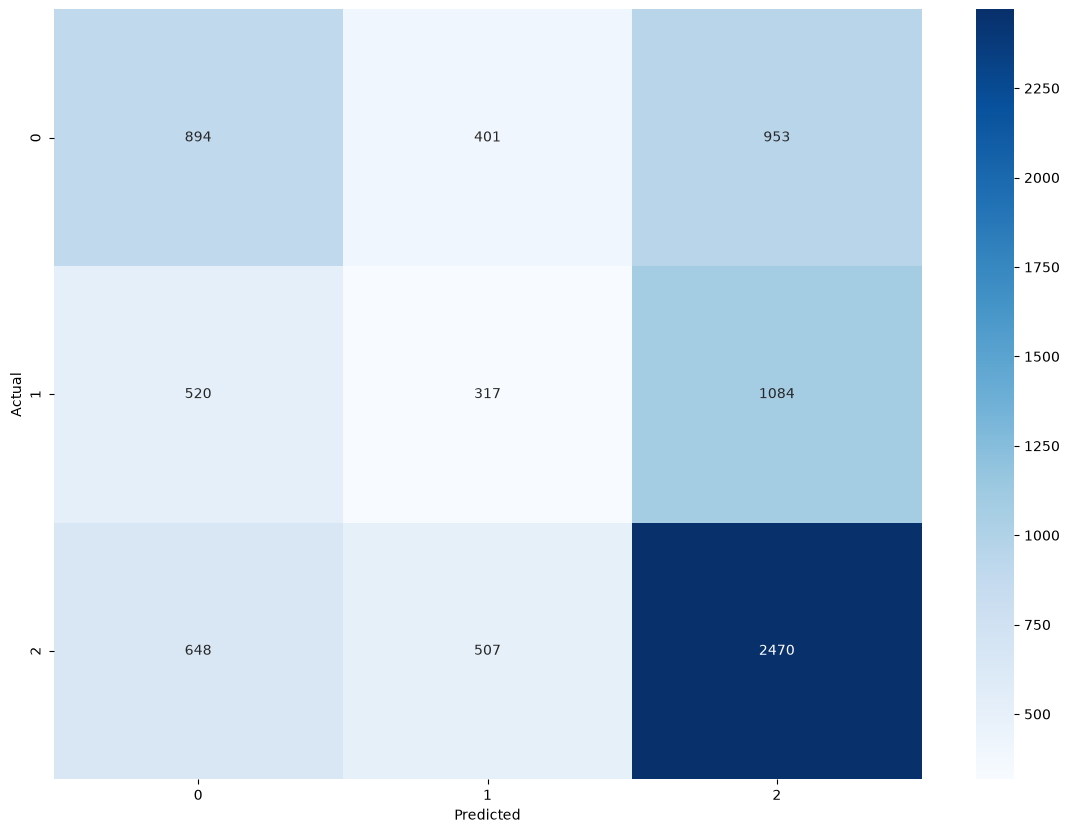

In [34]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [36]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")
mlflow.set_tracking_uri("http://127.0.0.1:5000")


dataset_v1 = mlflow.data.from_pandas(
    data_v1,
    name="dataset_v1",
    targets="FTR"
)

with mlflow.start_run(run_name="xgboost experiment 1"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_1.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.8391531481990652,
    "test_accuracy": 0.4722863741339492,

    "precision_away": 0.43,
    "recall_away": 0.40,

    "precision_draw": 0.26,
    "recall_draw": 0.17,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_1, name="XGBClassifier_r1")



2026/10/14 16:54:36 INFO mlflow.tracking.fluent: Experiment with name 'Football_match_prediction' does not exist. Creating a new experiment.


🏃 View run xgboost experiment 1 at: http://127.0.0.1:5000/#/experiments/1/runs/582f9e5333dc4bd7b2a4a79f038f7381
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 1: Evaluation

The initial XGBoost model shows significant overfitting, with training accuracy of 83.92% compared to test accuracy of 47.23%. Performance is particularly weak for draws (Class 1), with a recall of just 17%. This experiment establishes our initial benchmark. Future experiments will focus on hyperparameter tuning to reduce overfitting and improve overall accuracy and class-wise recall.

---

## Experiment 2: XGBoost — Max Depth Tuning

This experiment investigates the impact of `max_depth` on XGBoost's performance by testing depths of 3, 4, 6, and 8 while keeping other hyperparameters unchanged. The objective is to reduce overfitting and improve generalization, focusing on overall accuracy and class-wise recall, particularly for draws (Class 1).

In [77]:
model_2 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=20, gamma=0, enable_categorical=True, random_state=1)

In [78]:
model_2.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [79]:
y_hat = model_2.predict(x_test)
y_hat_train = model_2.predict(x_train)

Evaluation

In [80]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.4722863741339492
Train Accuracy of the model is 0.8391531481990652


In [81]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.40      0.41      2248
           1       0.26      0.17      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



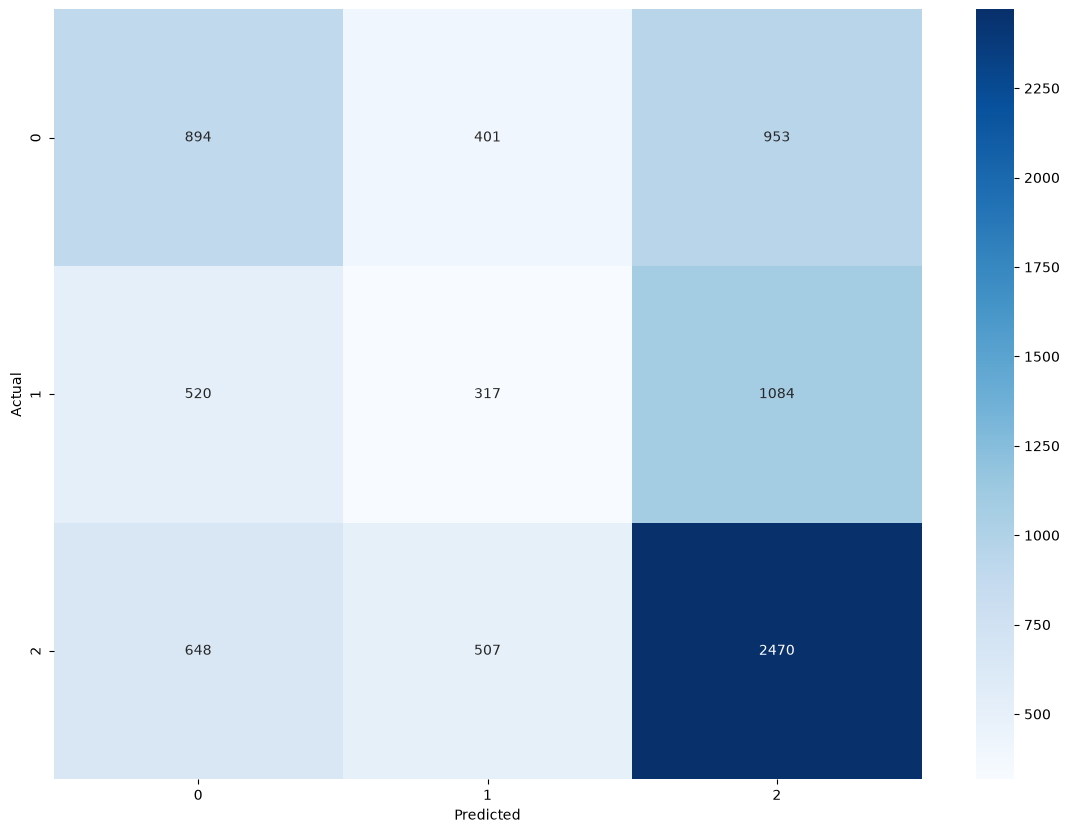

In [82]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [83]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="xgboost experiment 2"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_2.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.8391531481990652,
    "test_accuracy": 0.4722863741339492,

    "precision_away": 0.43,
    "recall_away": 0.40,

    "precision_draw": 0.26,
    "recall_draw": 0.17,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_2, name="XGBClassifier_r2")



🏃 View run xgboost experiment 2 at: http://127.0.0.1:5000/#/experiments/1/runs/08efa8eaa88542338828daae6425320b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 2: Evaluation

Among the tested values, `max_depth=8` delivered the best overall performance, with more balanced results across all three classes. Reducing tree depth did not improve generalization or class-wise recall, so a depth of 8 remains the preferred choice for further experiments.

---

## Experiment 3: XGBoost — Regularization Tuning

This experiment investigates `min_child_weight`, `gamma`, and `reg_lambda` while retaining `max_depth=8`. The objective is to reduce overfitting through stronger model restrictions and identify the best configuration based on overall accuracy and class-wise recall.

In [147]:
model_3 = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1, min_child_weight=5, gamma=0, reg_alpha=0, reg_lambda=1 ,enable_categorical=True, random_state=1)

In [148]:
model_3.fit(x_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [149]:
y_hat = model_3.predict(x_test)
y_hat_train = model_3.predict(x_train)

Evaluation

In [150]:
print(f"Accuracy of the model is {accuracy_score(y_test, y_hat)}")
print(f"Train Accuracy of the model is {accuracy_score(y_train, y_hat_train)}")

Accuracy of the model is 0.472671285604311
Train Accuracy of the model is 0.852075886719824


In [151]:
print("classification_report")
print(classification_report(y_test, y_hat))

classification_report
              precision    recall  f1-score   support

           0       0.43      0.39      0.41      2248
           1       0.26      0.16      0.20      1921
           2       0.55      0.68      0.61      3625

    accuracy                           0.47      7794
   macro avg       0.41      0.41      0.41      7794
weighted avg       0.44      0.47      0.45      7794



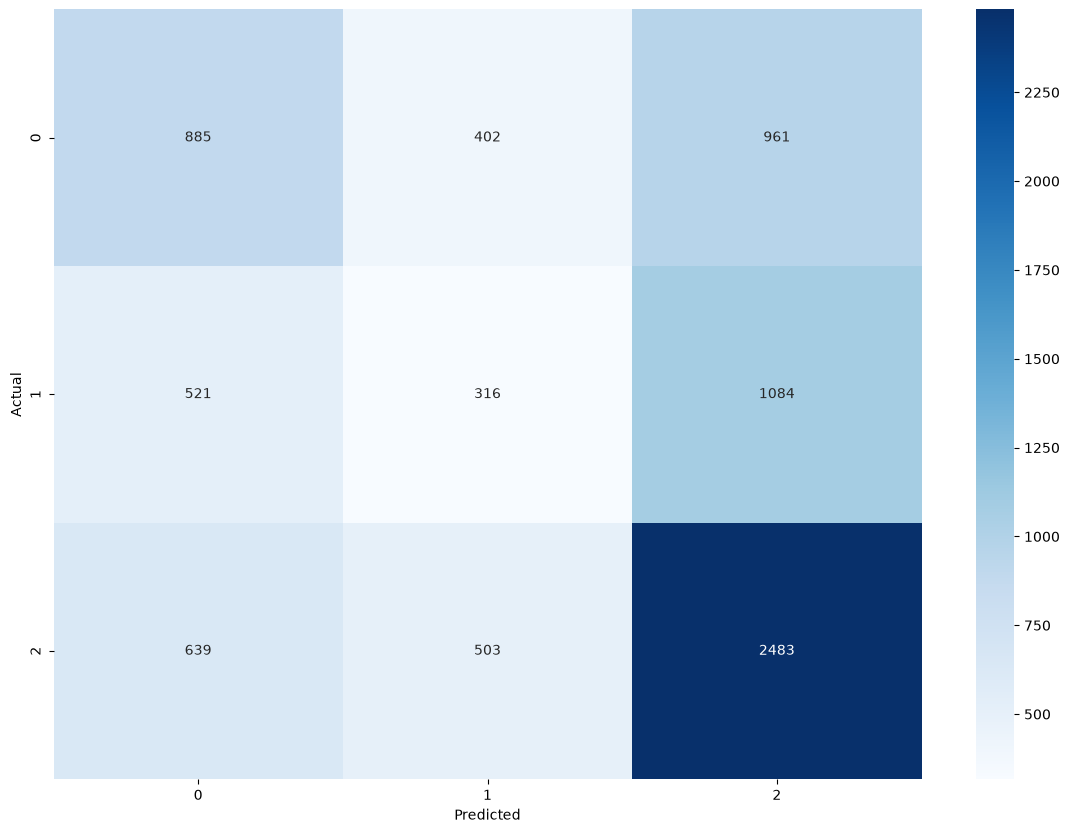

In [152]:
cm = confusion_matrix(y_test, y_hat)
plt.figure(figsize=(14,10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [153]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_match_prediction")

with mlflow.start_run(run_name="xgboost experiment 3"):
    mlflow.log_input(dataset_v1, context="source")
    mlflow.log_params(model_3.get_params())

    mlflow.log_metrics({
    "train_accuracy": 0.852075886719824,
    "test_accuracy": 0.472671285604311,

    "precision_away": 0.43,
    "recall_away": 0.39,

    "precision_draw": 0.26,
    "recall_draw": 0.16,

    "precision_home": 0.55,
    "recall_home": 0.68
}
)

    mlflow.xgboost.log_model(model_3, name="XGBClassifier_r3")



🏃 View run xgboost experiment 3 at: http://127.0.0.1:5000/#/experiments/1/runs/b1ebafef60ec4b00a540581804d9b133
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


### Experiment 3: Evaluation

Regularization tuning (`min_child_weight`, `gamma`, `reg_lambda`, and `reg_alpha`) produced no meaningful overall improvement. The model still shows significant overfitting, with 85.21% training accuracy and 47.27% test accuracy. Stronger L1 regularization and gamma reduced overfitting but compromised Class 1 (Draw) recall. Overall, regularization alone was insufficient to improve generalization and balanced class performance.

---